# Tomografía sísmica 3D con PINN

Este cuaderno invierte un **modelo de velocidad 3D** a partir de tiempos de primera llegada usando una
**red neuronal informada por la física (PINN)** que resuelve la ecuación eikonal.

**Pasos**
1. Cargar los datos (1344 tiempos sintéticos de `data/3d/`).
2. Definir las redes y la pérdida física.
3. Entrenar.
4. Evaluar: cortes del modelo, recuperación de las anomalías y validación independiente con Fast Marching.
5. Ver el bloque 3D interactivo.

> Sitio web con el resultado: https://amoacodc.github.io/Tomografia-PINNs/

## 1. Física

La ecuación eikonal relaciona el tiempo de viaje $T$ desde una fuente $\mathbf{x}_s$ con la velocidad $v$:

$$|\nabla T(\mathbf{x};\mathbf{x}_s)| = \frac{1}{v(\mathbf{x})}$$

Usamos la forma **factorizada** $T = T_0\,\tau$ con $T_0 = |\mathbf{x}-\mathbf{x}_s|$. Así $T(\mathbf{x}_s)=0$ se cumple
por construcción y la singularidad del frente de onda en la fuente queda absorbida en $T_0$.

Se entrenan **dos redes a la vez**:

| Red | Entrada | Salida |
|---|---|---|
| `tau_net` | (x, y, z, xₛ, yₛ, zₛ) | τ > 0 → tiempo de viaje para cualquier fuente |
| `v_net` | (x, y, z) | v ∈ [v<sub>min</sub>, v<sub>max</sub>] → **modelo de velocidad invertido** |

Pérdida:

$$\mathcal{L} = w_{pde}\,\big\| v\,|\nabla T| - 1 \big\|^2 \;+\; w_{data}\,\big\| T(\mathbf{x}_r;\mathbf{x}_s) - T_{obs}\big\|^2$$

El primer término obliga a cumplir la física en puntos aleatorios del cubo; el segundo, a ajustar los tiempos medidos.
No hace falta trazar rayos: el gradiente respecto a $v$ sale de la diferenciación automática.

## 2. Configuración

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt

from pinn_tomo.forward3d import Grid3D, true_velocity, traveltimes, anomaly_metrics
from pinn_tomo.pinn import TauNet, VelocityNet, eikonal_residual, traveltime

torch.manual_seed(0)
print("PyTorch", torch.__version__, "| hilos:", torch.get_num_threads())

PyTorch 2.15.0+cu132 | hilos: 4


In [2]:
# Hiperparámetros (los mismos que run_tomography_3d.py por defecto)
ITERS     = 25000   # bájalo a ~3000 para una prueba rápida (resultado más suave)
LR        = 1e-3
N_COLLOC  = 4000    # puntos de colocación por iteración
W_PDE     = 100.0
W_DATA    = 1.0
VMIN, VMAX = 1.0, 4.0
V_WIDTH, TAU_WIDTH = 96, 64

## 3. Datos

`data/3d/tiempos.csv` tiene una fila por par fuente–receptor. Los datos son **sintéticos**: se calcularon con
Fast Marching sobre un modelo conocido (gradiente vertical + una anomalía lenta + una rápida) y se les sumó
ruido gaussiano de 1 ms. Para usar datos reales basta con reemplazar este archivo con el mismo formato
(coordenadas en km dentro del cubo [0, 1]³).

In [3]:
DATA = ROOT / "data" / "3d"
tab = np.loadtxt(DATA / "tiempos.csv", delimiter=",", skiprows=1)
src = np.loadtxt(DATA / "fuentes.csv", delimiter=",", skiprows=1)[:, 1:]
rec = np.loadtxt(DATA / "receptores.csv", delimiter=",", skiprows=1)[:, 1:]
t_obs = np.zeros((len(src), len(rec)))
t_obs[tab[:, 0].astype(int), tab[:, 4].astype(int)] = tab[:, 8]

print(open(DATA / "tiempos.csv").readline().strip())
print(f"{len(src)} fuentes x {len(rec)} receptores = {t_obs.size} tiempos")
print(f"T entre {t_obs.min():.3f} y {t_obs.max():.3f} s")

id_fuente,xs_km,ys_km,zs_km,id_receptor,xr_km,yr_km,zr_km,t_obs_s,t_sin_ruido_s
12 fuentes x 112 receptores = 1344 tiempos
T entre 0.064 y 0.585 s


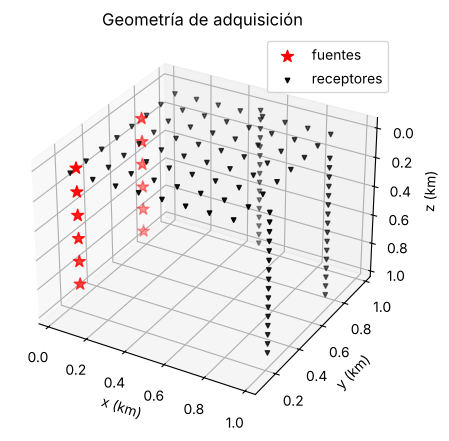

In [4]:
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*src.T, c="r", marker="*", s=80, label="fuentes")
ax.scatter(*rec.T, c="k", marker="v", s=10, label="receptores")
ax.set(xlabel="x (km)", ylabel="y (km)", zlabel="z (km)", title="Geometría de adquisición")
ax.invert_zaxis(); ax.legend()
plt.show()

Modelo verdadero (solo para comparar al final; la PINN **no** lo ve):

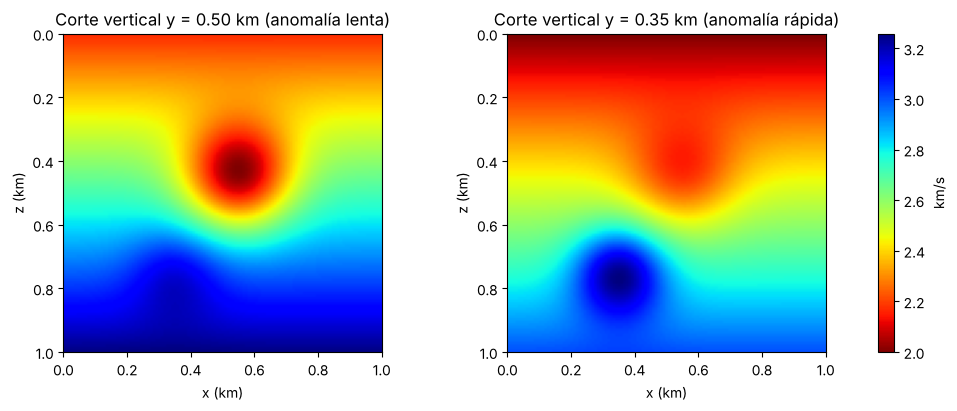

In [5]:
grid = Grid3D(n=121)
X, Y, Z = grid.mesh()
v_true = true_velocity(X, Y, Z)
ax_km = grid.axis
idx = lambda c: int(np.argmin(np.abs(ax_km - c)))

fig, axs = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axs[0].imshow(v_true[:, idx(0.50), :], extent=[0, 1, 1, 0], cmap="jet_r"); axs[0].set_title("Corte vertical y = 0.50 km (anomalía lenta)")
im = axs[1].imshow(v_true[:, idx(0.35), :], extent=[0, 1, 1, 0], cmap="jet_r"); axs[1].set_title("Corte vertical y = 0.35 km (anomalía rápida)")
for a in axs: a.set(xlabel="x (km)", ylabel="z (km)")
fig.colorbar(im, ax=axs, label="km/s"); plt.show()

## 4. Redes y entrenamiento

- `v_net` arranca con velocidad constante (2.5 km/s) y está acotada con una sigmoide entre `VMIN` y `VMAX`.
- En cada iteración se toman `N_COLLOC` puntos aleatorios del cubo, cada uno con una fuente al azar, para el residuo eikonal.
- El término de datos usa los 1344 tiempos observados.

In [6]:
S = torch.tensor(np.repeat(src, len(rec), axis=0), dtype=torch.float32)   # fuente de cada dato
R = torch.tensor(np.tile(rec, (len(src), 1)), dtype=torch.float32)        # receptor de cada dato
T_obs = torch.tensor(t_obs.reshape(-1, 1), dtype=torch.float32)
src_t = torch.tensor(src, dtype=torch.float32)
t_scale = float(T_obs.mean())

v_net = VelocityNet(VMIN, VMAX, width=V_WIDTH, dim=3)
tau_net = TauNet(s_ref=2.0 / (VMIN + VMAX), width=TAU_WIDTH, dim=3)
params = list(v_net.parameters()) + list(tau_net.parameters())
opt = torch.optim.Adam(params, lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=ITERS, eta_min=LR * 0.02)
print("parámetros:", sum(p.numel() for p in params))

parámetros: 49730


In [7]:
hist = {"it": [], "pde": [], "data": [], "rms_ms": []}
t0 = time.time()
for it in range(ITERS + 1):
    # residuo de la ecuación eikonal en puntos aleatorios
    xyz = torch.rand(N_COLLOC, 3)
    sxyz = src_t[torch.randint(len(src_t), (N_COLLOC,))]
    l_pde = (eikonal_residual(tau_net, v_net, xyz, sxyz) ** 2).mean()
    # ajuste a los tiempos observados
    t_pred = traveltime(tau_net, R, S)
    l_data = (((t_pred - T_obs) / t_scale) ** 2).mean() * 1e3

    loss = W_PDE * l_pde + W_DATA * l_data
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()

    if it % 250 == 0:
        rms = float(torch.sqrt(((t_pred.detach() - T_obs) ** 2).mean())) * 1e3
        hist["it"].append(it); hist["pde"].append(l_pde.item()); hist["data"].append(l_data.item()); hist["rms_ms"].append(rms)
        if it % 2500 == 0:
            print(f"it {it:6d} | pde {l_pde.item():.2e} | data {l_data.item():.2e} | rms {rms:5.2f} ms | {time.time()-t0:5.0f} s")

it      0 | pde 3.64e-01 | data 6.75e+01 | rms 99.41 ms |     0 s


it   2500 | pde 1.53e-04 | data 4.86e-02 | rms  2.67 ms |    48 s


it   5000 | pde 7.09e-05 | data 1.86e-02 | rms  1.65 ms |    92 s


it   7500 | pde 4.72e-05 | data 1.48e-02 | rms  1.47 ms |   134 s


it  10000 | pde 2.15e-05 | data 8.55e-03 | rms  1.12 ms |   177 s


it  12500 | pde 2.12e-05 | data 9.12e-03 | rms  1.16 ms |   219 s


it  15000 | pde 1.35e-05 | data 7.74e-03 | rms  1.07 ms |   263 s


it  17500 | pde 9.02e-06 | data 6.83e-03 | rms  1.00 ms |   308 s


it  20000 | pde 7.92e-06 | data 6.52e-03 | rms  0.98 ms |   355 s


it  22500 | pde 6.98e-06 | data 6.28e-03 | rms  0.96 ms |   402 s


it  25000 | pde 7.08e-06 | data 6.18e-03 | rms  0.95 ms |   446 s


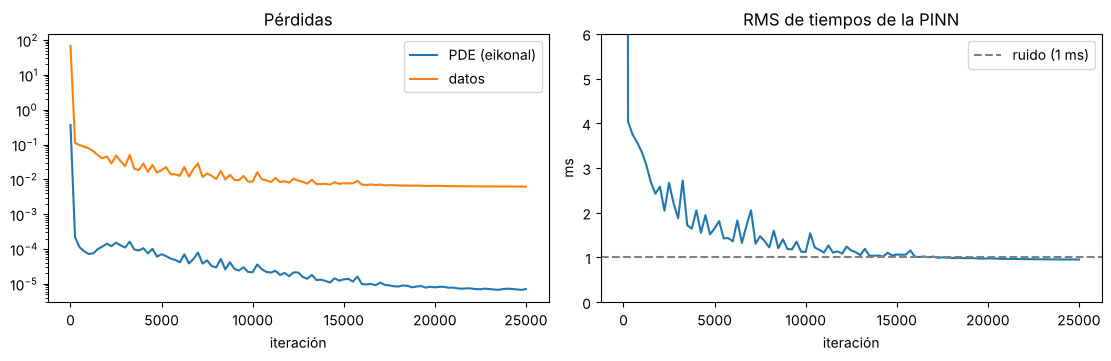

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
axs[0].semilogy(hist["it"], hist["pde"], label="PDE (eikonal)")
axs[0].semilogy(hist["it"], hist["data"], label="datos")
axs[0].set(title="Pérdidas", xlabel="iteración"); axs[0].legend()
axs[1].plot(hist["it"], hist["rms_ms"]); axs[1].axhline(1.0, ls="--", c="gray", label="ruido (1 ms)")
axs[1].set(title="RMS de tiempos de la PINN", xlabel="iteración", ylabel="ms", ylim=(0, 6)); axs[1].legend()
plt.show()

## 5. Resultado

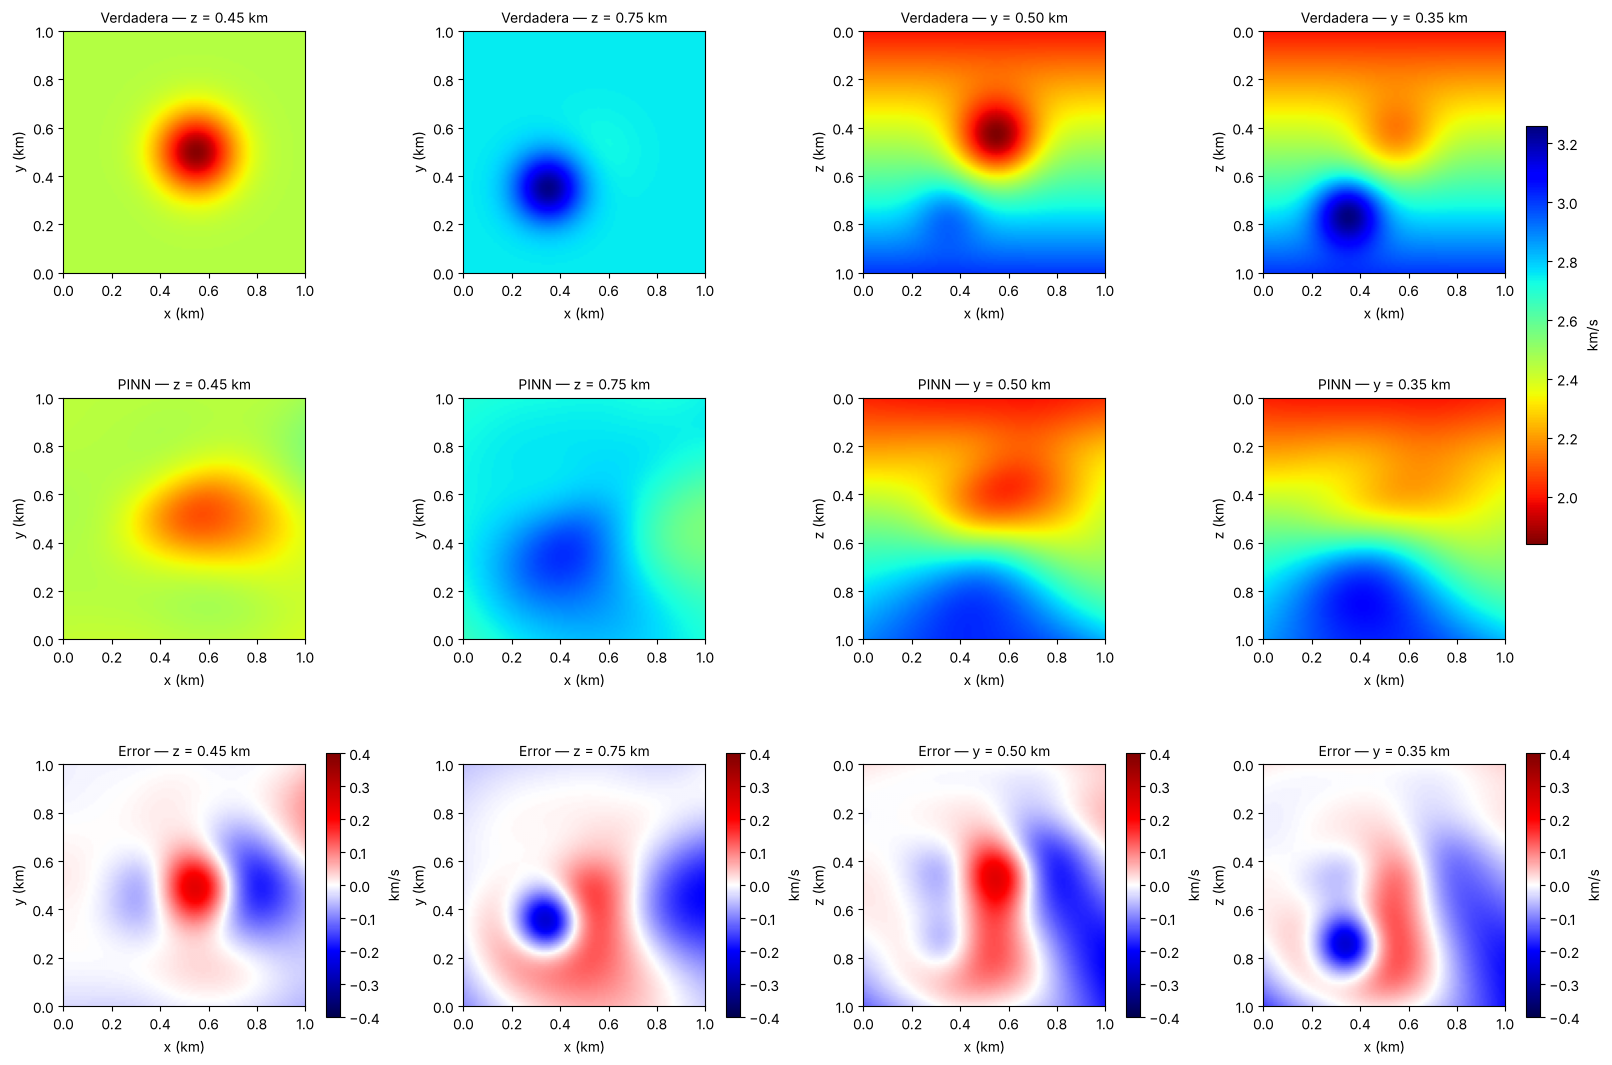

In [9]:
with torch.no_grad():
    pts = torch.tensor(np.stack([X.ravel(), Y.ravel(), Z.ravel()], 1), dtype=torch.float32)
    v_inv = torch.cat([v_net(c) for c in pts.split(200_000)]).numpy().reshape(X.shape)

cuts = [("z = 0.45 km", lambda v: v[idx(0.45)], True), ("z = 0.75 km", lambda v: v[idx(0.75)], True),
        ("y = 0.50 km", lambda v: v[:, idx(0.50), :], False), ("y = 0.35 km", lambda v: v[:, idx(0.35), :], False)]
fig, axs = plt.subplots(3, 4, figsize=(16, 11), constrained_layout=True)
for j, (name, f, horiz) in enumerate(cuts):
    ext, org = ([0, 1, 0, 1], "lower") if horiz else ([0, 1, 1, 0], "upper")
    for i, (data, lab, cmap, lim) in enumerate([(f(v_true), "Verdadera", "jet_r", (v_true.min(), v_true.max())),
                                                 (f(v_inv), "PINN", "jet_r", (v_true.min(), v_true.max())),
                                                 (f(v_inv) - f(v_true), "Error", "seismic", (-0.4, 0.4))]):
        im = axs[i, j].imshow(data, extent=ext, origin=org, cmap=cmap, vmin=lim[0], vmax=lim[1])
        axs[i, j].set_title(f"{lab} — {name}", fontsize=10)
        axs[i, j].set(xlabel="x (km)", ylabel="y (km)" if horiz else "z (km)")
    fig.colorbar(im, ax=axs[2, j], shrink=0.8, label="km/s")
fig.colorbar(axs[0, 3].images[0], ax=axs[:2, 3], shrink=0.6, label="km/s")
plt.show()

### Validación independiente

Las tiempos predichos por la propia PINN podrían ajustar los datos sin que la velocidad sea consistente.
Para comprobarlo, se recalculan los tiempos sobre el modelo invertido con **Fast Marching** (un solver
eikonal clásico, independiente de la red) y se comparan con los observados.

In [10]:
t_fmm_inv = traveltimes(v_inv, grid, src, rec)
t_fmm_ini = traveltimes(np.full_like(v_true, (VMIN + VMAX) / 2), grid, src, rec)
rms = lambda d: 1e3 * np.sqrt(np.mean(d ** 2))

print(f"RMS tiempos, modelo inicial (2.5 km/s): {rms(t_fmm_ini - t_obs):6.2f} ms")
print(f"RMS tiempos, modelo PINN (FMM)        : {rms(t_fmm_inv - t_obs):6.2f} ms   (ruido = 1 ms)")
print(f"Error relativo de velocidad           : {100*np.linalg.norm(v_inv-v_true)/np.linalg.norm(v_true):6.2f} %")
for k, val in anomaly_metrics(v_inv, grid).items():
    print(f"{k:42s}: {val:6.2f}")

RMS tiempos, modelo inicial (2.5 km/s):  37.78 ms
RMS tiempos, modelo PINN (FMM)        :   1.20 ms   (ruido = 1 ms)
Error relativo de velocidad           :   1.99 %
anomalia_lenta_amplitud_recuperada_%      :  60.03
anomalia_lenta_rmse_km_s                  :   0.09
anomalia_rapida_amplitud_recuperada_%     :  50.58
anomalia_rapida_rmse_km_s                 :   0.08


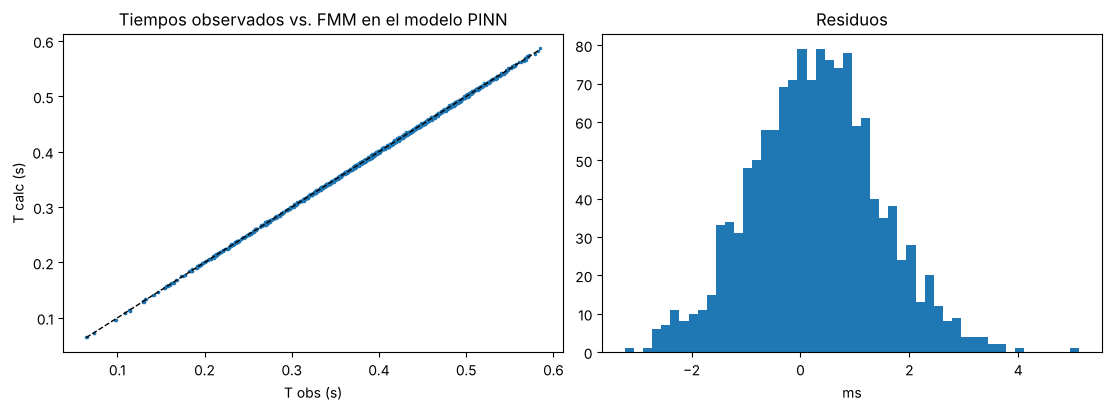

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axs[0].plot(t_obs.ravel(), t_fmm_inv.ravel(), ".", ms=3); lim = [t_obs.min(), t_obs.max()]
axs[0].plot(lim, lim, "k--", lw=1); axs[0].set(title="Tiempos observados vs. FMM en el modelo PINN", xlabel="T obs (s)", ylabel="T calc (s)")
axs[1].hist(1e3 * (t_fmm_inv - t_obs).ravel(), bins=50); axs[1].set(title="Residuos", xlabel="ms")
plt.show()

## 6. Bloque 3D interactivo

Cubo con una esquina recortada: la cara vertical $y = 0.5$ atraviesa la anomalía lenta y el piso $z = 0.75$ muestra
la anomalía rápida. Se puede rotar con el ratón.

> GitHub no muestra gráficos interactivos al ver el cuaderno; para eso ejecútalo en Jupyter / VS Code / Colab
> o mira el sitio web.

In [12]:
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"  # Jupyter, VS Code y Colab
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.interpolate import RegularGridInterpolator
from plot_block_3d import block_faces

CUT = (0.30, 0.50, 0.75)
panels = [("Verdadero", v_true, "Jet_r", v_true.min(), v_true.max()),
          ("PINN", v_inv, "Jet_r", v_true.min(), v_true.max()),
          ("Error", v_inv - v_true, "RdBu_r", -0.4, 0.4)]
fig = make_subplots(rows=1, cols=3, specs=[[{"type": "scene"}] * 3], subplot_titles=[p[0] for p in panels])
for k, (_, v, cs, lo, hi) in enumerate(panels):
    interp = RegularGridInterpolator((ax_km, ax_km, ax_km), v)
    for j, (x, y, z, c) in enumerate(block_faces(interp, CUT, n=41)):
        fig.add_trace(go.Surface(x=x, y=y, z=z, surfacecolor=c, colorscale=cs, cmin=lo, cmax=hi,
                                 showscale=(j == 0 and k > 0), lighting=dict(ambient=1, diffuse=0, specular=0),
                                 colorbar=dict(len=0.6, x=0.655 if k == 1 else 1.0)), row=1, col=k + 1)
scene = dict(zaxis=dict(range=[1, 0], title="z (km)"), xaxis_title="x (km)", yaxis_title="y (km)",
             aspectmode="cube", camera=dict(eye=dict(x=1.6, y=-1.6, z=1.1)))
fig.update_layout(scene=scene, scene2=scene, scene3=scene, height=520, margin=dict(l=0, r=0, t=40, b=0))
fig.show()

## 7. Guardar

Guarda los pesos de las redes para reutilizar el modelo sin reentrenar.

In [13]:
out = ROOT / "outputs_3d"; out.mkdir(exist_ok=True)
torch.save({"v_net": v_net.state_dict(), "tau_net": tau_net.state_dict()}, out / "model_notebook.pt")
print("Guardado en", (out / "model_notebook.pt").relative_to(ROOT))

Guardado en outputs_3d/model_notebook.pt


## Para seguir

- **Más entrenamiento** (`ITERS = 40000`) suele mejorar aún más las anomalías.
- **Geometría densa:** cambia `DATA` a `data/3d_densa` (27 fuentes); necesita más iteraciones.
- **Datos reales:** reemplaza `data/3d/` con tus tiempos (mismo formato CSV, coordenadas normalizadas a [0, 1]³) y ajusta `VMIN/VMAX`.